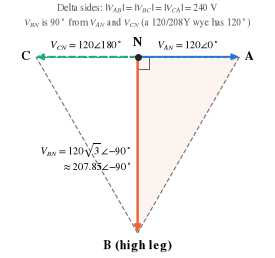

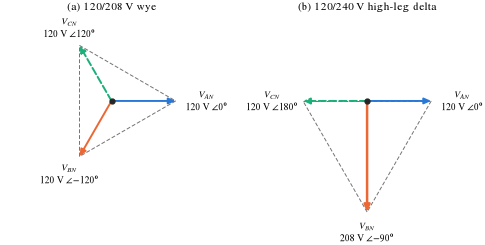

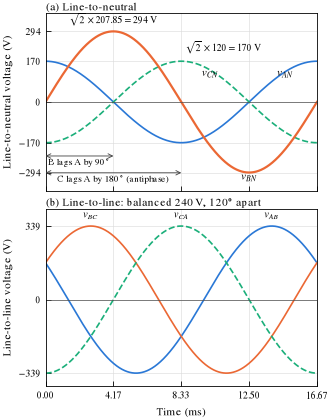

In [2]:
# High-leg delta figures: phasor diagram, wye vs delta, waveforms.
# Open in VS Code: each "# %%" block runs as a cell (Run Cell), or run the whole file.
# Output: figures/*.pdf (for Overleaf) and *.png (preview).

# %% Cell 1 — style + helpers
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from pathlib import Path

# figures/ at the repo root, whether this runs from the root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "STIXGeneral", "mathtext.fontset": "stix",   # Times-like, as IEEE
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
    "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.2,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "axes.grid": True, "grid.linewidth": 0.4, "grid.color": "0.85",
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
COL_W, PAGE_W = 3.5, 7.16           # IEEE single / double column widths, inches

# One colour per line, used in every figure. B = high leg = orange.
C = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "N": "0.15", "LL": "0.45"}
LS = {"A": "-", "B": "-", "C": "--"}  # C dashed so print/greyscale still separates A and C

def P(mag, deg):
    return mag * np.exp(1j * np.deg2rad(deg))

# Phasors of the 120/240 V centre-tapped closed delta (V_AN reference)
V_AN = P(120, 0);  V_CN = -V_AN
V_AB = P(240, 60); V_BC = P(240, -60); V_CA = P(240, 180)
V_BN = -V_AB + V_AN

def arrow(ax, z0, z1, color, lw=1.4, ls="-"):
    ax.annotate("", xy=(z1.real, z1.imag), xytext=(z0.real, z0.imag),
                arrowprops=dict(arrowstyle="-|>,head_length=0.5,head_width=0.22",
                                color=color, lw=lw, linestyle=ls,
                                shrinkA=0, shrinkB=0))

# %% Cell 2 — phasor diagram of the high-leg delta
fig, ax = plt.subplots(figsize=(COL_W, 3.3))
ax.set_aspect("equal"); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks([]); ax.set_yticks([])

A, B, Cc, N = V_AN, V_BN, V_CN, 0j            # node positions measured from N

# shade the B-N-A right triangle used for the Pythagoras check
ax.add_patch(Polygon([(N.real, N.imag), (A.real, A.imag), (B.real, B.imag)],
                     closed=True, fc=C["B"], alpha=0.08, ec="none"))
# right-angle marker at N
s = 14
ax.plot([s, s, 0], [0, -s, -s], color="0.3", lw=0.6)

# delta sides (line-to-line), thin grey
for z0, z1 in [(A, B), (B, Cc), (Cc, A)]:
    ax.plot([z0.real, z1.real], [z0.imag, z1.imag], color=C["LL"], lw=0.8, ls=(0, (4, 2)))

# line-to-neutral phasors from N
arrow(ax, N, A, C["A"]); arrow(ax, N, Cc, C["C"], ls="--"); arrow(ax, N, B, C["B"], lw=1.8)
ax.plot(0, 0, "o", color=C["N"], ms=4, zorder=5)

# labels: text in ink, colour carried by the arrow
ax.text(0, 9, "N", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.text(A.real + 6, 0, "A", ha="left", va="center", fontsize=9, fontweight="bold")
ax.text(Cc.real - 6, 0, "C", ha="right", va="center", fontsize=9, fontweight="bold")
ax.text(0, B.imag - 8, "B (high leg)", ha="center", va="top", fontsize=9, fontweight="bold")
ax.text(60, 6, r"$V_{AN}=120\angle0^\circ$", ha="center", va="bottom", fontsize=7.5)
ax.text(-60, 6, r"$V_{CN}=120\angle180^\circ$", ha="center", va="bottom", fontsize=7.5)
ax.text(-6, -120, r"$V_{BN}=120\sqrt{3}\angle{-90^\circ}$" "\n" r"$\approx 207.85\angle{-90^\circ}$",
        ha="right", va="center", fontsize=7.5)
ax.text(0, 30, r"Delta sides: $|V_{AB}|=|V_{BC}|=|V_{CA}|=240$ V" "\n"
        r"$V_{BN}$ is $90^\circ$ from $V_{AN}$ and $V_{CN}$ (a 120/208Y wye has $120^\circ$)",
        ha="center", va="bottom", fontsize=7, color="0.3")
ax.set_xlim(-160, 160); ax.set_ylim(-235, 60)
fig.savefig(FIG / "hl-phasor.pdf"); fig.savefig(FIG / "hl-phasor.png")

# %% Cell 3 — wye vs high-leg delta, side by side
fig, axs = plt.subplots(1, 2, figsize=(PAGE_W * 0.72, 2.6))
cases = {
    "(a) 120/208 V wye": {"A": P(120, 0), "B": P(120, -120), "C": P(120, 120)},
    "(b) 120/240 V high-leg delta": {"A": V_AN, "B": V_BN, "C": V_CN},
}
for ax, (title, ph) in zip(axs, cases.items()):
    ax.set_aspect("equal"); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    nodes = [ph["A"], ph["B"], ph["C"]]
    for i in range(3):
        z0, z1 = nodes[i], nodes[(i + 1) % 3]
        ax.plot([z0.real, z1.real], [z0.imag, z1.imag], color=C["LL"], lw=0.7, ls=(0, (4, 2)))
    for k in "ABC":
        arrow(ax, 0j, ph[k], C[k], lw=1.8 if (k == "B" and "delta" in title) else 1.4, ls=LS[k])
        z = ph[k]; u = z / abs(z)
        ang = round(np.rad2deg(np.angle(z))); ang = 180 if ang == -180 else ang
        lz = z + (58 if abs(u.imag) < 0.1 else 38) * u
        ax.text(lz.real, lz.imag, f"$V_{{{k}N}}$\n{abs(z):.0f} V ∠{ang}°".replace("-", "−"),
                ha="center", va="center", fontsize=7, linespacing=1.1)
    ax.plot(0, 0, "o", color=C["N"], ms=3.5, zorder=5)
    ax.set_title(title, fontsize=8, pad=2)
    ax.set_xlim(-205, 205); ax.set_ylim(-265, 165)
fig.tight_layout(w_pad=0.5)
fig.savefig(FIG / "wye-vs-hl-phasor.pdf"); fig.savefig(FIG / "wye-vs-hl-phasor.png")

# %% Cell 4 — waveforms over one cycle (60 Hz)
f = 60.0; T = 1 / f
t = np.linspace(0, T, 1000); tm = t * 1e3                    # ms
def v(Vph):  # instantaneous value of an RMS phasor
    return np.sqrt(2) * abs(Vph) * np.cos(2 * np.pi * f * t + np.angle(Vph))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(COL_W, 4.4), sharex=True)

# (a) line-to-neutral
for k, Vph in [("A", V_AN), ("C", V_CN), ("B", V_BN)]:
    ax1.plot(tm, v(Vph), color=C[k], ls=LS[k], lw=1.6 if k == "B" else 1.2)
ax1.axhline(0, color="0.3", lw=0.5)
ax1.set_ylabel("Line-to-neutral voltage (V)")
ax1.set_ylim(-370, 370); ax1.set_yticks([-294, -170, 0, 170, 294])
ax1.set_title("(a) Line-to-neutral", loc="left", fontsize=8, pad=2)
# direct labels, placed where the curves are well apart
for txt, x, y, ha in [(r"$v_{AN}$", 15.2, 120, "right"),
                      (r"$v_{CN}$", 9.6, 120, "left"),
                      (r"$v_{BN}$", 12.5, -312, "center")]:
    ax1.text(x, y, txt, ha=ha, va="center", fontsize=8)
# peak values, written above each peak
ax1.text(4.17, 312, r"$\sqrt{2}\times207.85=294$ V", ha="center", va="bottom", fontsize=7)
ax1.text(8.6, 196, r"$\sqrt{2}\times120=170$ V", ha="left", va="bottom", fontsize=7)
# time-shift brackets from the A peak (t = 0)
def bracket(ax, x0, x1, y, txt):
    ax.annotate("", xy=(x1, y), xytext=(x0, y),
                arrowprops=dict(arrowstyle="<->", lw=0.6, color="0.25", shrinkA=0, shrinkB=0))
    ax.text((x0 + x1) / 2, y - 10, txt, ha="center", va="top", fontsize=6.8)
bracket(ax1, 0, T / 4 * 1e3, -225, r"B lags A by $90^\circ$")
bracket(ax1, 0, T / 2 * 1e3, -295, r"C lags A by $180^\circ$ (antiphase)")

# (b) line-to-line
for name, Vph, k in [("AB", V_AB, "A"), ("BC", V_BC, "B"), ("CA", V_CA, "C")]:
    ax2.plot(tm, v(Vph), color=C[k], ls=LS[k], lw=1.2)
    i = np.argmax(v(Vph))
    ax2.annotate(f"$v_{{{name}}}$", (tm[i], v(Vph)[i]), xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontsize=7.5)
ax2.axhline(0, color="0.3", lw=0.5)
ax2.set_ylim(-400, 420); ax2.set_yticks([-339, 0, 339])
ax2.set_ylabel("Line-to-line voltage (V)")
ax2.set_xlabel("Time (ms)")
ax2.set_title("(b) Line-to-line: balanced 240 V, 120° apart", loc="left", fontsize=8, pad=2)
ax2.set_xlim(0, T * 1e3); ax2.set_xticks(np.round(np.arange(0, 5) * T / 4 * 1e3, 2))
fig.align_ylabels(); fig.tight_layout(h_pad=0.6)
fig.savefig(FIG / "hl-waveforms.pdf"); fig.savefig(FIG / "hl-waveforms.png")